# **Machine Learning Challenges and Applications**

This notebook continues from the learning methods in the [previous notebook](https://www.kaggle.com/code/muhammadf4h33m/01-machine-learning-foundations). It looks at common data and model challenges, then follows with examples of machine learning in different industries.

<!-- Source transcription: transcription/3.4.md -->
## **Challenges in ML**

<!-- Source transcription: transcription/3.4.md -->
Data and algorithms both matter. In practice, collecting and preparing suitable data can take more effort than selecting a model.

<!-- Source transcription: transcription/3.4.md -->
### **1. Data collection**

Data may be easy to find while learning, but collecting useful data for an industry problem can be difficult. A delivery service, for example, needs trip times and locations before it can estimate busy hours. Common sources include APIs and web scraping; Google is one example of a site from which information can be collected.

<!-- Source transcription: transcription/4.1.md -->
### **2. Insufficient or unlabeled data**

<!-- Source transcription: transcription/4.1.md -->
| Model | Algorithm | Available examples |
| --- | --- | ---: |
| M1 | Better algorithm | 100 |
| M2 | Simpler algorithm | $10^6$ |

Even when M1 uses a better algorithm, M2 may perform better because it has much more data, assuming that data is relevant and correctly labeled. More rows help only when they represent the problem and contain useful information.

Unlabeled data is another challenge. For image classification, scraped images still need labels such as “cat” or “dog” before a supervised model can learn from them. Collecting the pictures is only part of the work; someone or some process must provide reliable answers.

<!-- Source transcription: transcription/4.1.md -->
### **3. Non-representative data**

A dataset can tell only part of the story. If important groups are missing, a model may learn a pattern that does not represent the population it is meant to describe. For example, a model trained mostly on large cities may make weaker predictions for smaller towns.

<!-- Source transcription: transcription/4.1.md -->
The World Cup example contrasts data taken only from Pakistan (labeled “sampling noise”) with data from many countries but only Pakistani respondents (labeled “sampling bias”).

<!-- Source transcription: transcription/4.1.md -->
**Technical note:** A sample limited to Pakistan is an example of sampling bias when the target is all countries. Sampling noise refers to random variation between samples.

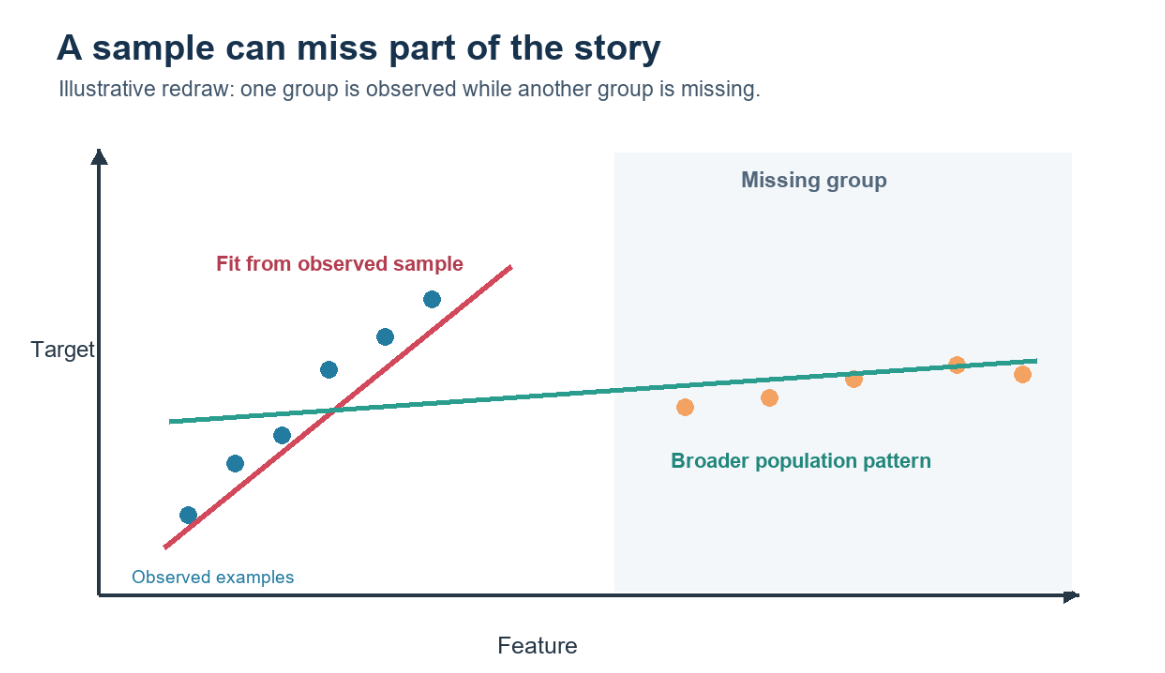

<!-- Source transcription: transcription/4.1.md -->
### **4. Poor-quality data**

“Garbage in, garbage out”: outliers, errors, and inconsistent formats can lead to poor results. A height entered in the wrong unit or a missing value treated as zero can mislead a model. Spending 80% of the time on data is a rough reminder to plan enough time for data work, not a fixed rule.

<!-- Source transcription: transcription/4.1.md -->
### **5. Irrelevant features**

Irrelevant features do not help the analysis. In a marathon example, age and weight may be useful, while location may not. Age and weight can also be combined into one feature through feature engineering. A column being available does not automatically make it useful for prediction.

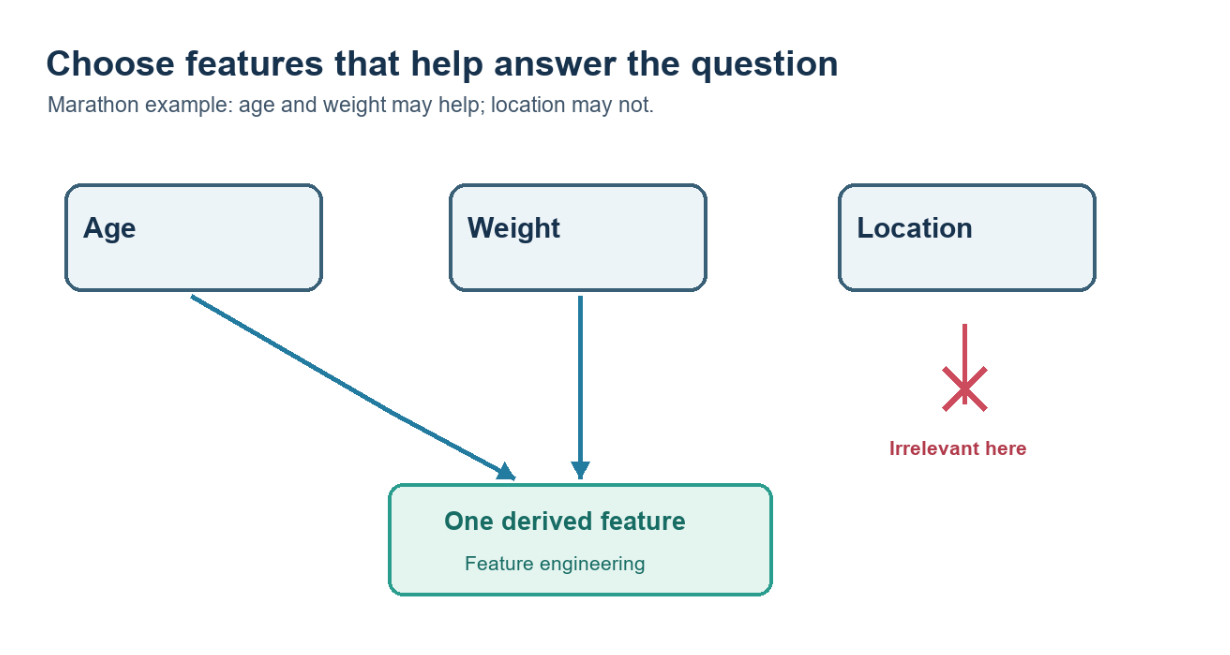

<!-- Source transcription: transcription/4.2.md -->
## **Overfitting and underfitting**

<!-- Source transcription: transcription/4.2.md -->
### **6. Overfitting**

An overfit model memorizes details in its training data instead of learning a pattern that generalizes. For example, seeing one expensive ticket in Karachi and assuming everything in Karachi is expensive overgeneralizes from one observation. Such a model can perform well on training data but poorly on unseen data.

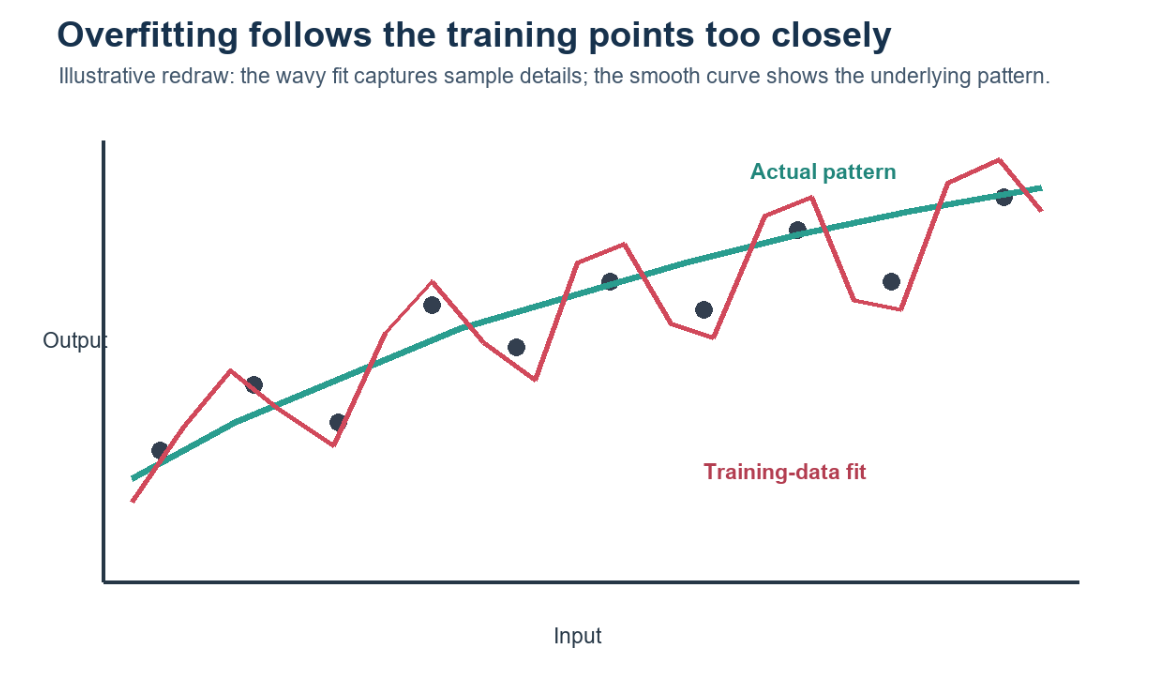

<!-- Source transcription: transcription/4.2.md -->
### **7. Underfitting**

An underfit model is too simple to capture the pattern, so it performs poorly on both training data and unseen data. On a curved relationship, a straight line may miss the trend even among examples the model has already seen.

A useful check is to compare error on the data used for fitting with error on held-out data:

<!-- Source transcription: transcription/4.2.md -->
$$
\mathrm{MSE}_{\text{train}} = \frac{1}{n_{\text{train}}} \sum_{i=1}^{n_{\text{train}}} (y_i - \hat{y}_i)^2,\qquad
\mathrm{MSE}_{\text{test}} = \frac{1}{n_{\text{test}}} \sum_{i=1}^{n_{\text{test}}} (y_i - \hat{y}_i)^2.
$$

A very simple model can have high error on both sets. A highly complex model may have low training error but much higher test error.

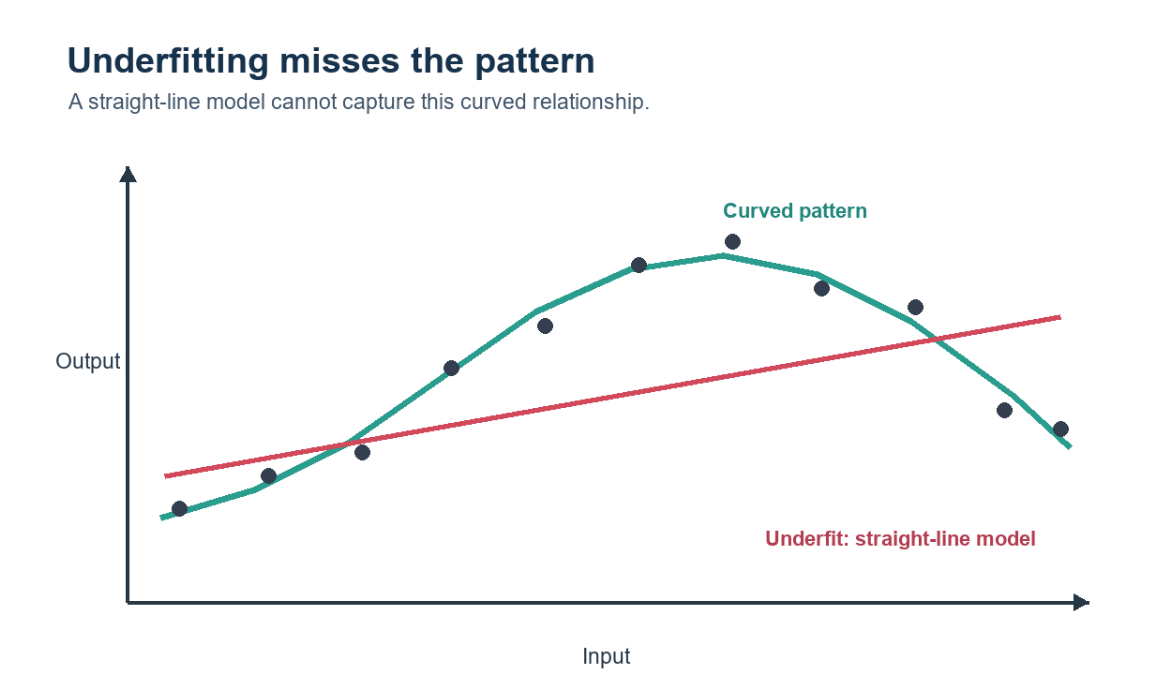

This small example compares polynomial models of different degrees on a noisy sine curve. The degree controls how flexible each model can be.

`np.polyfit` estimates the coefficients for the selected polynomial degree, and `np.polyval` uses them to make predictions.


In [ ]:
import numpy as np

# Create a noisy sine-wave dataset.
data_rng = np.random.default_rng(7)
x = np.sort(data_rng.uniform(-3, 3, 50))
y = np.sin(1.5 * x) + data_rng.normal(0, 0.3, size=len(x))

# Keep a separate test set for checking generalization.
split_rng = np.random.default_rng(2)
indices = split_rng.permutation(len(x))
test_indices = indices[:13]
train_indices = indices[13:]
x_train, y_train = x[train_indices], y[train_indices]
x_test, y_test = x[test_indices], y[test_indices]

print(f"{'Degree':<10}{'Training MSE':<18}{'Test MSE'}")
for degree in (1, 4, 12):
    coefficients = np.polyfit(x_train, y_train, degree)
    train_predictions = np.polyval(coefficients, x_train)
    test_predictions = np.polyval(coefficients, x_test)
    train_mse = np.mean((y_train - train_predictions) ** 2)
    test_mse = np.mean((y_test - test_predictions) ** 2)
    print(f'{degree:<10}{train_mse:<18.3f}{test_mse:.3f}')

Degree    Training MSE      Test MSE
1         0.598             0.332
4         0.126             0.092
12        0.042             0.608


Degree 1 is too simple here and has relatively high error on both sets. Degree 4 fits the pattern better. Degree 12 lowers training error further, but its test error rises, showing overfitting on this split. This is a small demonstration, not a rule that degree 12 always overfits.

<!-- Source transcription: transcription/4.2.md -->
### **8. Software integration**

Integrating an ML model into software can be difficult, even when the model itself works. Library compatibility and how the model interacts with existing systems need attention; the app must also send data in the format the model expects. Direct database access can affect software, so the connection needs to be planned carefully.

<!-- Source transcription: transcription/4.2.md -->
### **9. Offline learning and deployment**

With offline learning, new data may require training and deploying the model again. Repeating this process can make deployment costly and slow. If customer behavior changes between updates, the deployed model can also become stale.

<!-- Source transcription: transcription/4.2.md -->
### **10. Compute cost**

Running ML models on servers costs money and computing resources. A model that is accurate but takes too long to respond may not fit a live app; higher traffic can also increase server costs.

Building end-to-end software and engaging users are part of the broader work often called MLOps. User feedback can reveal when a model’s output is confusing or no longer useful.

<!-- Source transcription: transcription/4.3.md -->
## **Applications of ML**

<!-- Source transcription: transcription/4.3.md -->
### **1. Retail: Amazon and Bazaar**

Sales data can help retailers decide which products to stock and which categories are popular. With a large catalog such as Amazon’s 6 crore products, these patterns can guide stock choices, gym-product recommendations, targeted ads, and product positioning using association-rule learning.

<!-- Source transcription: transcription/4.3.md -->
### **2. Banking and finance**

Before awarding a loan, a bank can compare an applicant’s profile with patterns in past defaults. It can also use customer and location patterns to consider where to open branches and which promotions to offer; the model supports those decisions rather than making them automatically.

<!-- Source transcription: transcription/4.3.md -->
### **3. Transport: OLA and Uber**

Driver apps can forecast demand and identify busy areas at office times (sometimes shown as 2× or 3× demand). The service can then position enough drivers, suggest routes, and choose a useful target when a driver has more than one passenger.

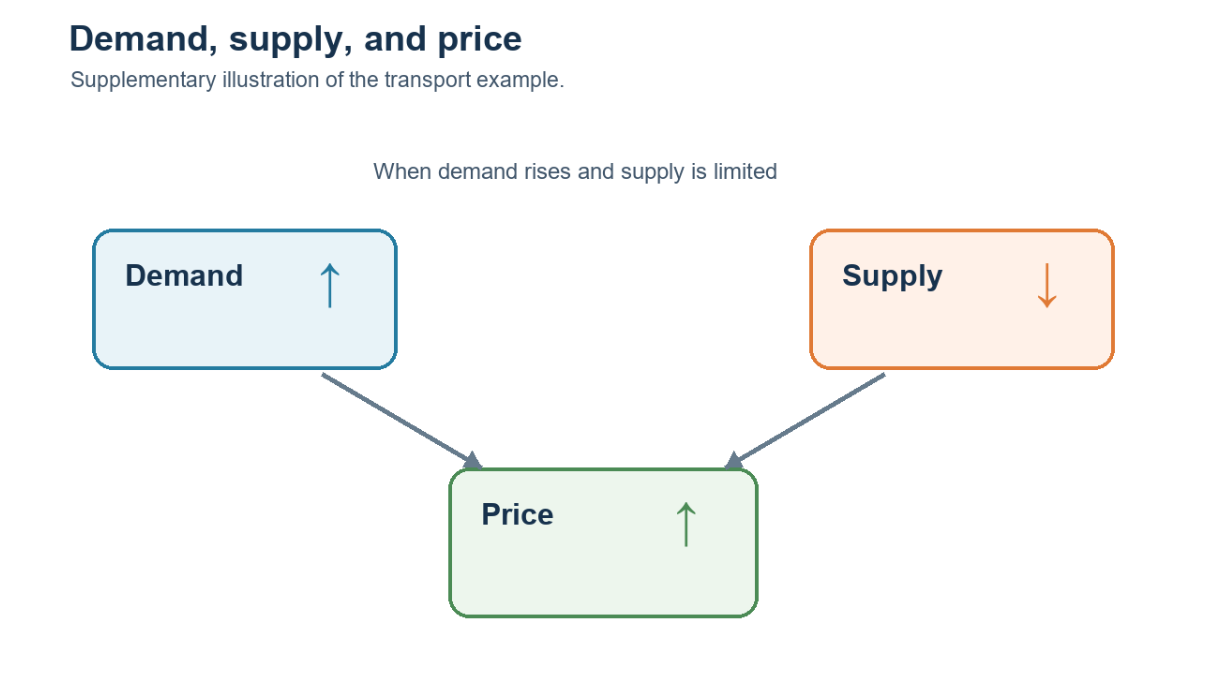

The demand-and-supply note describes why a busy area can have higher prices. The diagram is a simplified relationship, not a complete pricing model.

<!-- Source transcription: transcription/4.3.md -->
### **4. Manufacturing: Tesla**

Manufacturing applications include automating work with robotic arms, using sensors and IoT data to detect defects, and predicting maintenance needs before equipment fails. Catching a defect or warning sign early can help a team act before more products or equipment are affected.

<!-- Source transcription: transcription/4.3.md -->
### **5. Consumer internet**

Sentiment analysis sorts text by the opinion it expresses—for example, whether a review sounds positive or negative. Social-media sentiment can be studied around elections or markets, but the examples linking election outcomes or PMLN sentiment with share prices are not guaranteed predictions. A collection of public opinion may also be useful to companies; verify the historical claim that Twitter started generating revenue through sentiment analysis before publishing.

<!-- Source transcription: transcription/4.4.md -->
Sentiment can summarize expressed opinions, but it does not by itself establish or reliably predict election or stock-market outcomes. The claim that Twitter started generating revenue through sentiment analysis is historical and should be verified before publication.